In [1]:
import pandas as pd # for data manipulation
import numpy as np # for numerical computation
import matplotlib.pyplot as plt # for statistic plots
import seaborn as sns #for statistical plots

In [2]:
# loading the titanic training dataset
df= pd.read_csv ("titanic_train.csv")

In [3]:
# loading the titanic dataset
df_1= pd.read_csv ("gender_submission.csv")

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
# convert the data types
df['Survived'] = df['Survived'].astype('category')
df['Pclass'] = df['Pclass'].astype('category')
df['Sex'] = df['Sex'].astype('category')
df['Cabin'] = df['Cabin'].astype('category')
df['Embarked'] = df['Embarked'].astype('category')
df['PassengerId']= df['PassengerId'].astype('object')

df.describe()

,Age,SibSp,Parch,Fare
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,0.523008,0.381594,32.204208
std,14.526497,1.102743,0.806057,49.693429
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,0.000000,0.000000,7.910400
50%,28.000000,0.000000,0.000000,14.454200
75%,38.000000,1.000000,0.000000,31.000000
max,80.000000,8.000000,6.000000,512.329200


In [7]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [8]:
# detect missing values
missing_values= df.isnull().sum()
print (missing_values)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [9]:
# handle missing values
df['Age'].fillna(df['Age'].median(), inplace=True)
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)
# drop column with too many missing values
df= df.drop(columns= ['Cabin'])

/tmp/ipykernel_3983/1932515063.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)
/tmp/ipykernel_3983/1932515063.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

In [10]:
df.nunique()

,0
PassengerId,891
Survived,2
Pclass,3
Name,891
Sex,2
Age,88
SibSp,7
Parch,7
Ticket,681
Fare,248


In [11]:
duplicates= df.duplicated()
print (duplicates)

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Length: 891, dtype: bool


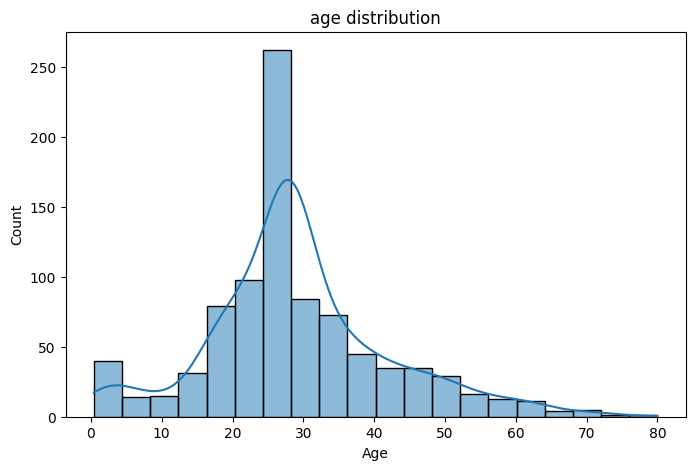

In [12]:
# a histogram for age
plt.figure(figsize=(8,5))
sns.histplot(df['Age'].dropna(), bins= 20, kde= True)
plt.title ('age distribution')
plt.xlabel ('Age')
plt.ylabel ('Count')
plt.show()

/tmp/ipykernel_3983/619883249.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot (x='Embarked', data= df, palette= 'deep')


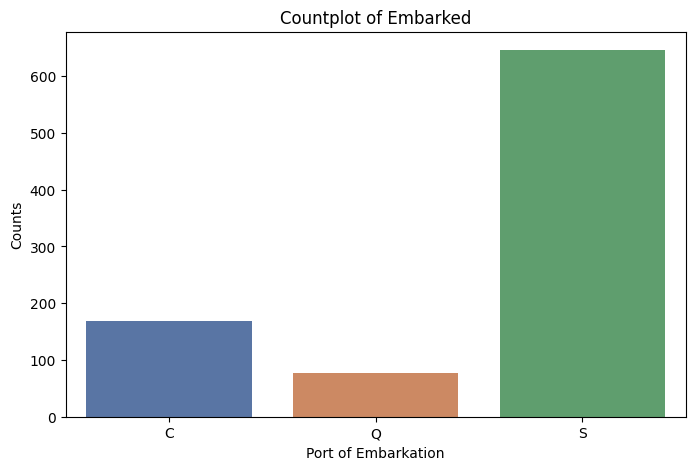

In [13]:
# countplot for Embarked to show how many passengers embarked from each location
plt.figure (figsize= (8,5))
sns.countplot (x='Embarked', data= df, palette= 'deep')
plt.title ('Countplot of Embarked')
plt.xlabel ('Port of Embarkation')
plt.ylabel ('Counts')
plt.show()

/tmp/ipykernel_3983/910365276.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot (df['Fare'], shade= True)


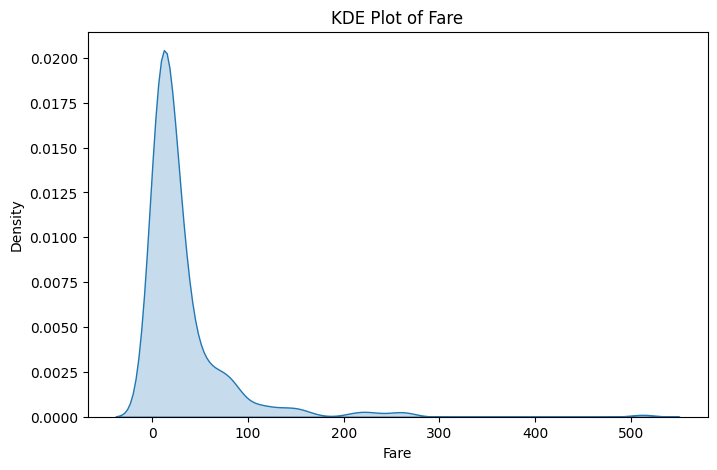

In [14]:
# skewness of ticket prices/fare
plt.figure (figsize= (8, 5))
sns.kdeplot (df['Fare'], shade= True)
plt.title ('KDE Plot of Fare')
plt.xlabel ('Fare')
plt.show()

/tmp/ipykernel_3983/3232664890.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot (x='Pclass', y='Fare', data= df, palette='deep')


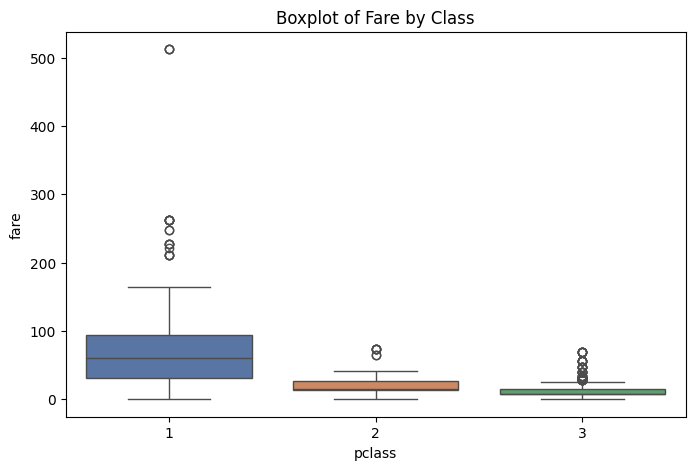

In [15]:
# boxplots of fare grouped by pclass to tell whether fare changes depending on pclass
plt.figure (figsize= (8,5))
sns.boxplot (x='Pclass', y='Fare', data= df, palette='deep')
plt.title('Boxplot of Fare by Class')
plt.xlabel('pclass')
plt.ylabel('fare')
plt.show()

/tmp/ipykernel_3983/2011129513.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x= 'Survived', y= 'Age', data= df, split= True, palette= 'muted')


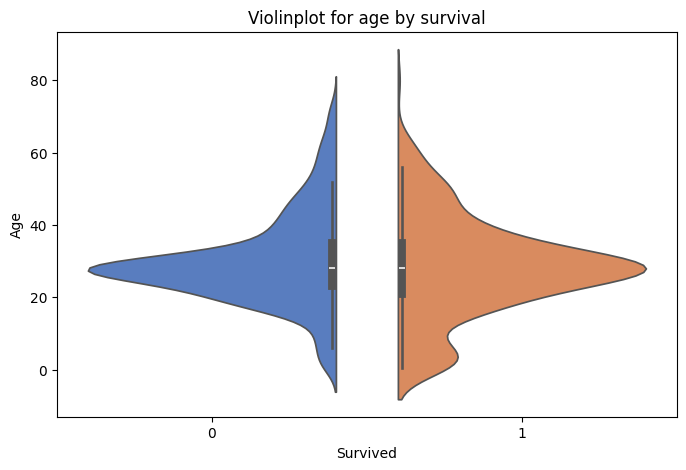

In [16]:
# violin plot to show whether the younger passengers are more likely to survive on the titanic
plt.figure (figsize= (8,5))
plt.title('Violinplot for age by survival')
sns.violinplot(x= 'Survived', y= 'Age', data= df, split= True, palette= 'muted')
plt.xlabel('Survived')
plt.ylabel('Age')
plt.show()

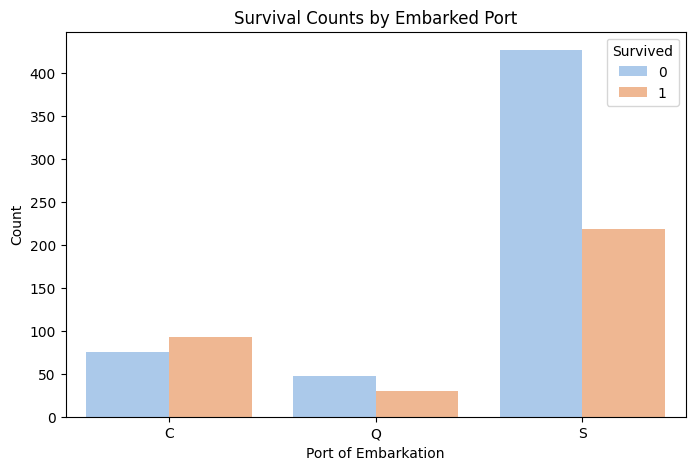

In [17]:
# grouped bar plot to show whether the Embarked point influenced survivcal rate
plt.figure(figsize=(8, 5))
sns.countplot(x='Embarked', hue='Survived', data=df, palette='pastel')
plt.title('Survival Counts by Embarked Port')
plt.xlabel('Port of Embarkation')
plt.ylabel('Count')
plt.show()

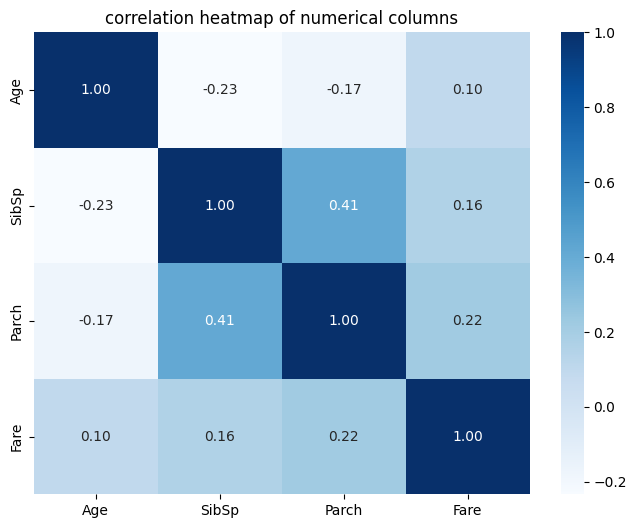

In [18]:
# correlation heatmap to show correlation for numerical columns
plt.figure (figsize=(8,6))
numerical_columns= ['Age', 'SibSp', 'Parch', 'Fare']
sns.heatmap(df[numerical_columns].corr(), annot= True, cmap='Blues', fmt='.2f')
plt.title('correlation heatmap of numerical columns')
plt.show()

<Figure size 1000x1000 with 0 Axes>

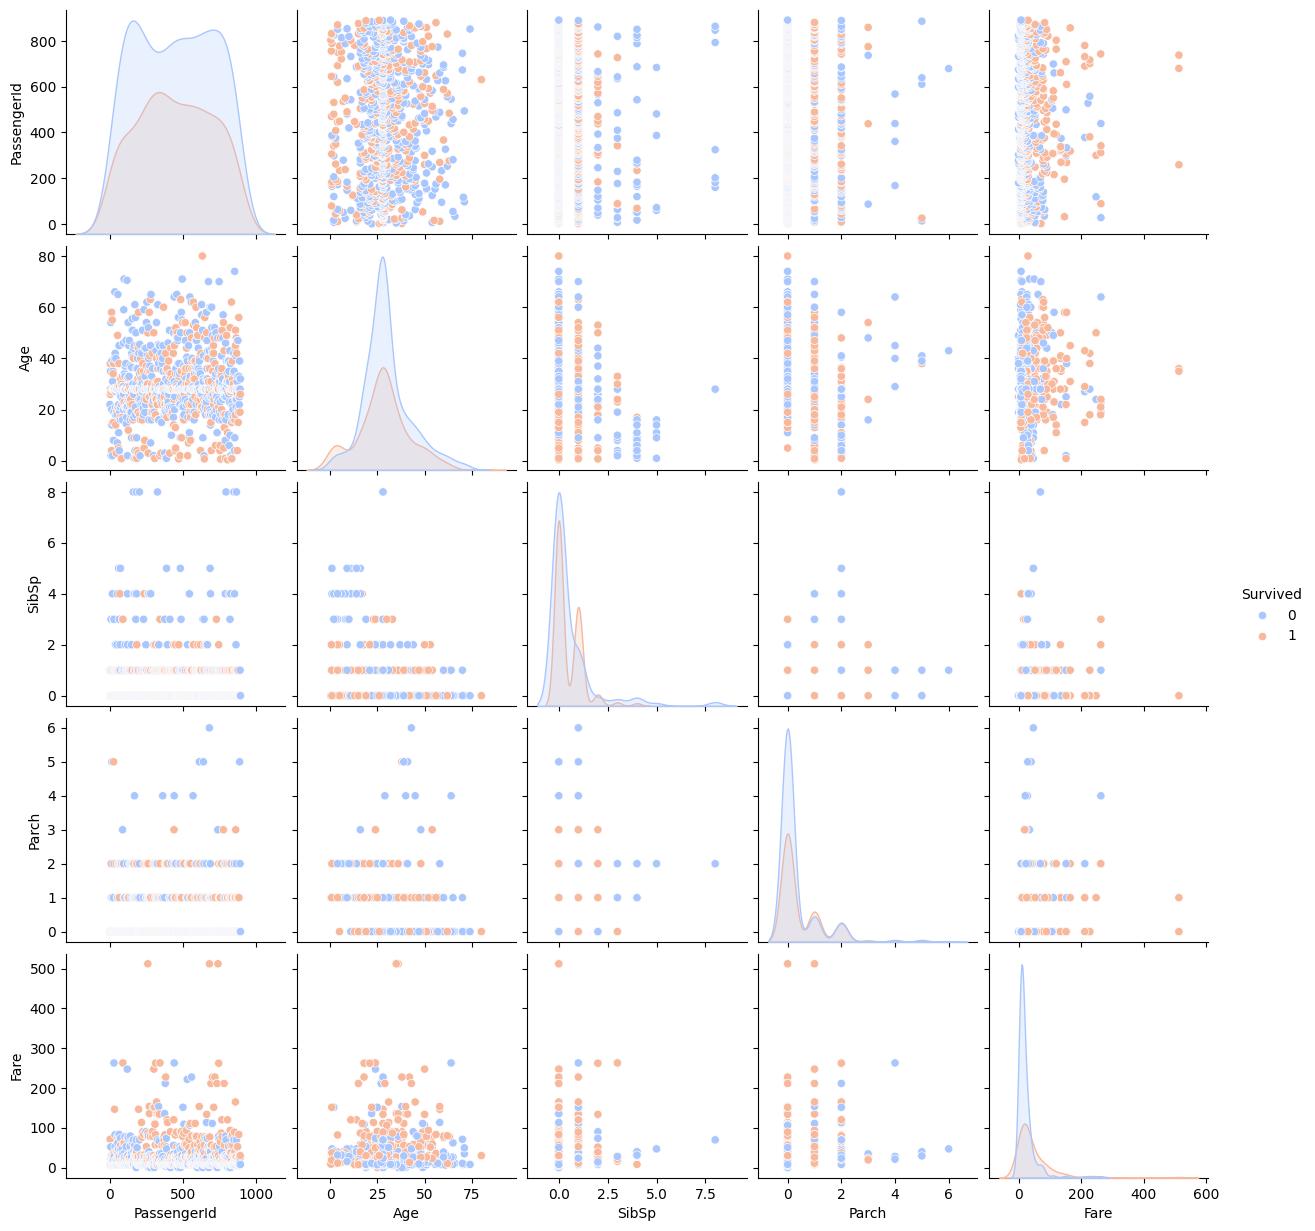

In [19]:
# Pair plot for numerical columns
plt.figure(figsize=(10, 10))
sns.pairplot(df, hue='Survived', diag_kind='kde', palette='coolwarm')
plt.show()

/tmp/ipykernel_3983/753262673.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Fare'], palette='pastel')


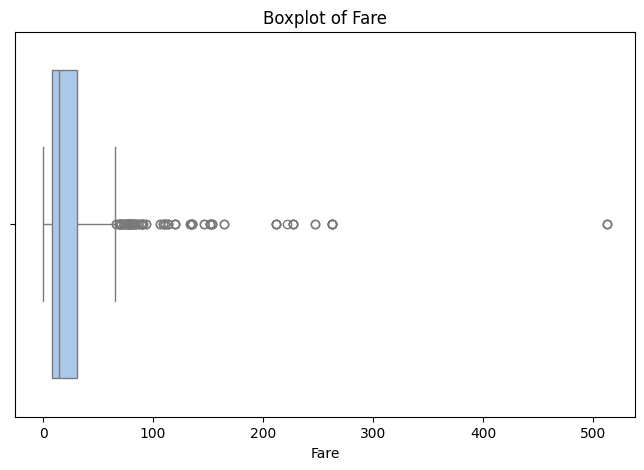

In [20]:
# Boxplot for Fare to detect outliers
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Fare'], palette='pastel')
plt.title('Boxplot of Fare')
plt.show()

/tmp/ipykernel_3983/255362912.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Age'], palette='pastel')


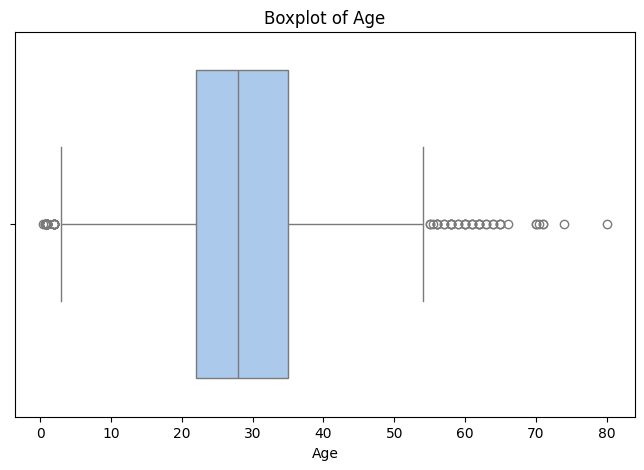

In [21]:
# Boxplot for Age to detect outliers
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Age'], palette='pastel')
plt.title('Boxplot of Age')
plt.show()

/tmp/ipykernel_3983/927138030.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived', data=df, palette='Set2')


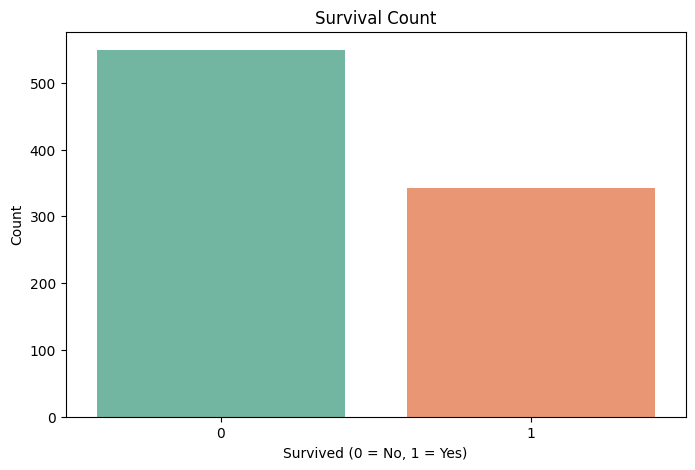

In [22]:
# Countplot for Survived
plt.figure(figsize=(8, 5))
sns.countplot(x='Survived', data=df, palette='Set2')
plt.title('Survival Count')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

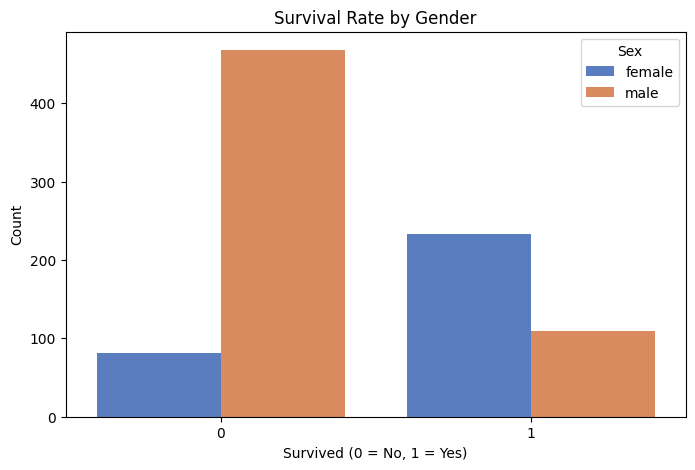

In [23]:
# Countplot for Survived grouped by Gender
plt.figure(figsize=(8, 5))
sns.countplot(x='Survived', hue='Sex', data=df, palette='muted')
plt.title('Survival Rate by Gender')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

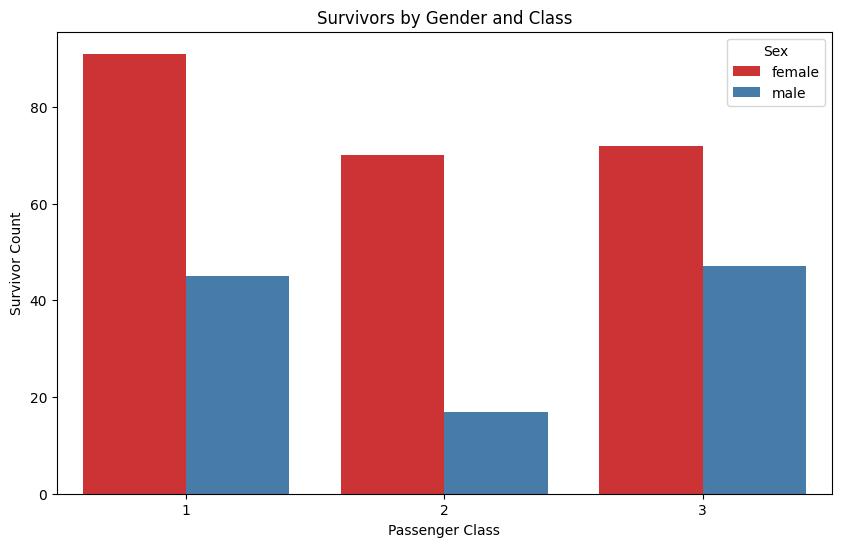

In [24]:
# Grouped bar plot for survival by Gender and Class
plt.figure(figsize=(10, 6))
sns.countplot(x='Pclass', hue='Sex', data=df[df['Survived'] == 1], palette='Set1')
plt.title('Survivors by Gender and Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survivor Count')
plt.show()

In [25]:
women = df.loc[df.Sex == 'female']["Survived"]
rate_women = sum(women)/len(women)

print("% of women who survived:", rate_women)

% of women who survived: 0.7420382165605095


In [26]:
men = df.loc[df.Sex == 'male']["Survived"]
rate_men = sum(men)/len(men)

print("% of men who survived:", rate_men)

% of men who survived: 0.18890814558058924


In [27]:
# Convert Survived column to numerical values

df['Survived_Numeric'] = df['Survived'].astype(int)

# Calculate survival rate by gender

gender_survival = df.groupby('Sex').agg(
    Total_Passengers=('Survived_Numeric', 'count'),
    Total_Survivors=('Survived_Numeric', 'sum'),
    Survival_Rate=('Survived_Numeric', 'mean')
)

gender_survival['Survival_Rate'] = (
    gender_survival['Survival_Rate'] * 100
)

print(gender_survival)

        Total_Passengers  Total_Survivors  Survival_Rate
Sex                                                     
female               314              233      74.203822
male                 577              109      18.890815


/tmp/ipykernel_3983/2768462649.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gender_survival = df.groupby('Sex').agg(


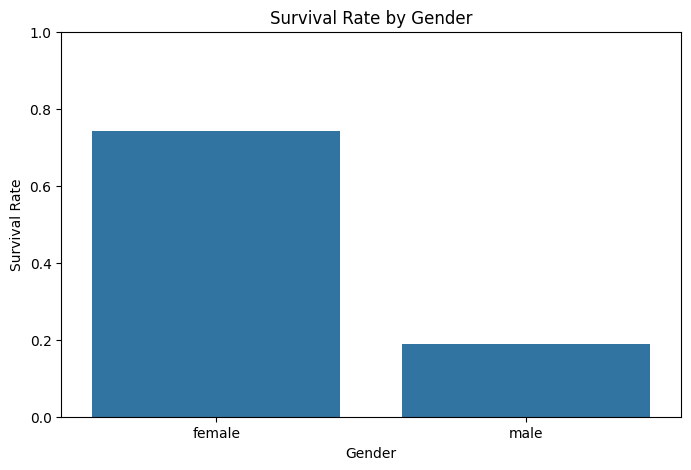

In [28]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Sex',
    y='Survived_Numeric',
    errorbar=None
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.ylim(0, 1)

plt.show()

In [29]:
# Survival rate by passenger class

class_survival = df.groupby('Pclass').agg(
    Total_Passengers=('Survived_Numeric', 'count'),
    Total_Survivors=('Survived_Numeric', 'sum'),
    Survival_Rate=('Survived_Numeric', 'mean')
)

class_survival['Survival_Rate'] *= 100

print(class_survival)

        Total_Passengers  Total_Survivors  Survival_Rate
Pclass                                                  
1                    216              136      62.962963
2                    184               87      47.282609
3                    491              119      24.236253


/tmp/ipykernel_3983/3867821354.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  class_survival = df.groupby('Pclass').agg(


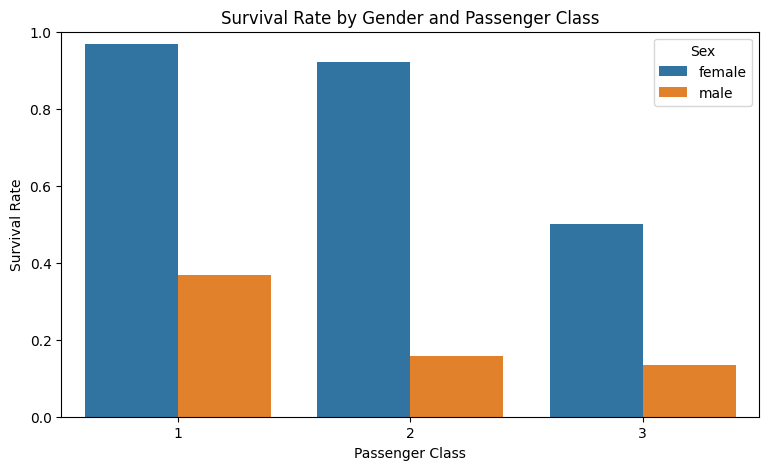

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Pclass',
    y='Survived_Numeric',
    hue='Sex',
    errorbar=None
)

plt.title("Survival Rate by Gender and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.ylim(0, 1)

plt.show()

In [31]:
# Survival rate by embarkation port

embarked_survival = df.groupby('Embarked').agg(
    Total_Passengers=('Survived_Numeric', 'count'),
    Total_Survivors=('Survived_Numeric', 'sum'),
    Survival_Rate=('Survived_Numeric', 'mean')
)

embarked_survival['Survival_Rate'] *= 100

print(embarked_survival)

          Total_Passengers  Total_Survivors  Survival_Rate
Embarked                                                  
C                      168               93      55.357143
Q                       77               30      38.961039
S                      646              219      33.900929


/tmp/ipykernel_3983/3951280336.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  embarked_survival = df.groupby('Embarked').agg(
